In [ ]:
import numpy
import pandas as pd
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
import nltk
from nltk.corpus import stopwords
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import numpy as np

df = pd.read_csv("C:\\Users\\Faiz\\Downloads\\Senarai Penyelidikan REER 2018-2025.csv")
df.columns = df.columns.str.strip()


In [28]:
df['Clean_Title']


0     phase three road surface condition monitoring ...
1                       exposure travelled risk hailing
2     identification junction treatment based best p...
3     malaysia road assesssment programme myrap star...
4     determination safe section design rural primar...
                            ...                        
83              traﬃc performance hard shoulder running
84    assessing feasibility point point speed enforc...
85                micromobility lane star rating module
86    pembangunan sistem pemantauan risiko kawasan s...
87    impact ops bersepadu reducing heavy vehicle re...
Name: Clean_Title, Length: 88, dtype: object

In [ ]:
title_col = None
for col in df.columns:
    if 'tajuk' in col.lower() or 'title' in col.lower():
        title_col = col
        break

if title_col is None:
    for col in df.columns:
        if df[col].dtype == 'object' and col not in ['Tahun', 'BIL.', 'KOD PROJEK', 'KETUA PROJEK']:
            title_col = col
            break

all_titles = ' '.join(df[title_col].astype(str).tolist())

custom_stopwords = set(stopwords.words('english'))
malay_stopwords = set(['dan', 'di', 'ke', 'pada', 'untuk', 'yang', 'dengan', 'oleh', 'adalah',
                       'kajian', 'studi', 'study', 'analysis', 'assessment', 'evaluation',
                       'development', 'research', 'projek', 'project'])
custom_stopwords.update(malay_stopwords)

def clean_text_for_viz(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\b\w{1,2}\b', '', text)
    words = text.split()
    words = [w for w in words if w not in custom_stopwords]
    return ' '.join(words)

df['Clean_Title'] = df[title_col].apply(clean_text_for_viz)
all_clean_titles = ' '.join(df['Clean_Title'].tolist())


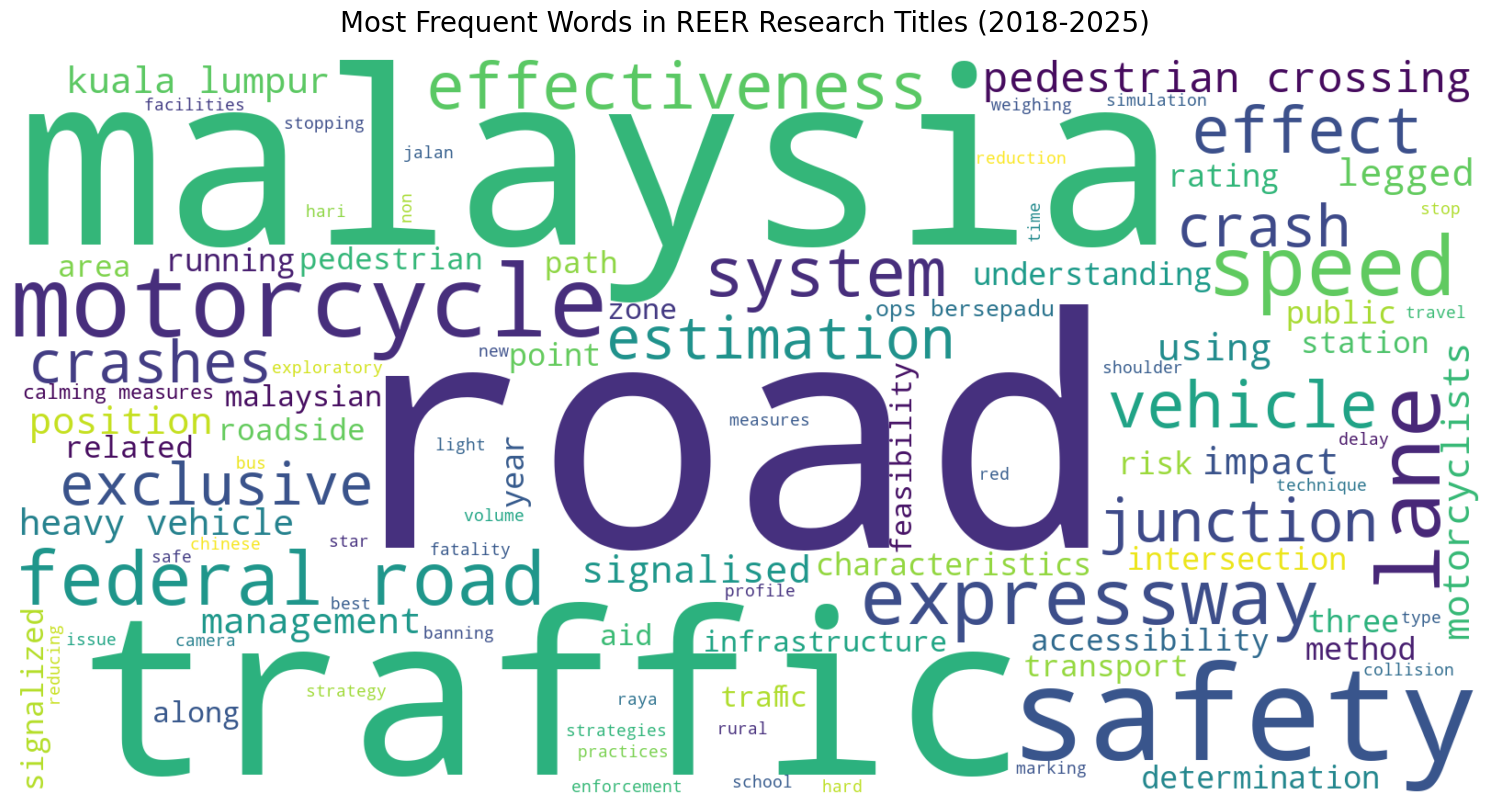

In [20]:
plt.figure(figsize=(15, 10))
wordcloud = WordCloud(
    width=1600, height=800, background_color='white',
    colormap='viridis', max_words=100,
    stopwords=custom_stopwords, contour_width=1, contour_color='steelblue'
).generate(all_clean_titles)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Words in REER Research Titles (2018-2025)', fontsize=20, pad=20)
plt.tight_layout()
plt.show()


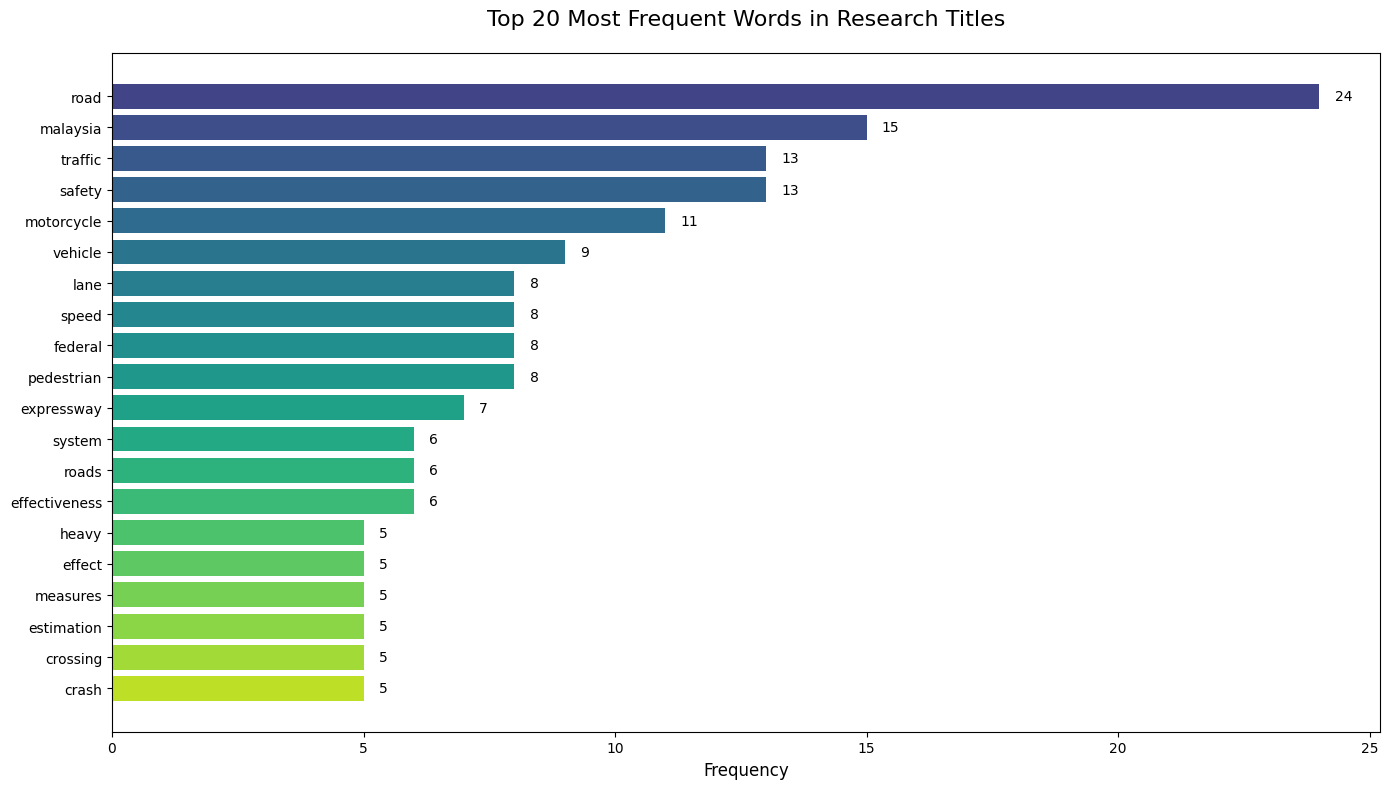

In [22]:
words = all_clean_titles.split()
word_freq = Counter(words)
top_words = word_freq.most_common(20)

plt.figure(figsize=(14, 8))
words_list, freqs = zip(*top_words)
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(words_list)))
bars = plt.barh(words_list, freqs, color=colors)
plt.xlabel('Frequency', fontsize=12)
plt.title('Top 20 Most Frequent Words in Research Titles', fontsize=16, pad=20)
plt.gca().invert_yaxis()
for bar, freq in zip(bars, freqs):
    width = bar.get_width()
    plt.text(width + 0.3, bar.get_y() + bar.get_height()/2, f'{freq}', ha='left', va='center', fontsize=10)
plt.tight_layout()
plt.show()


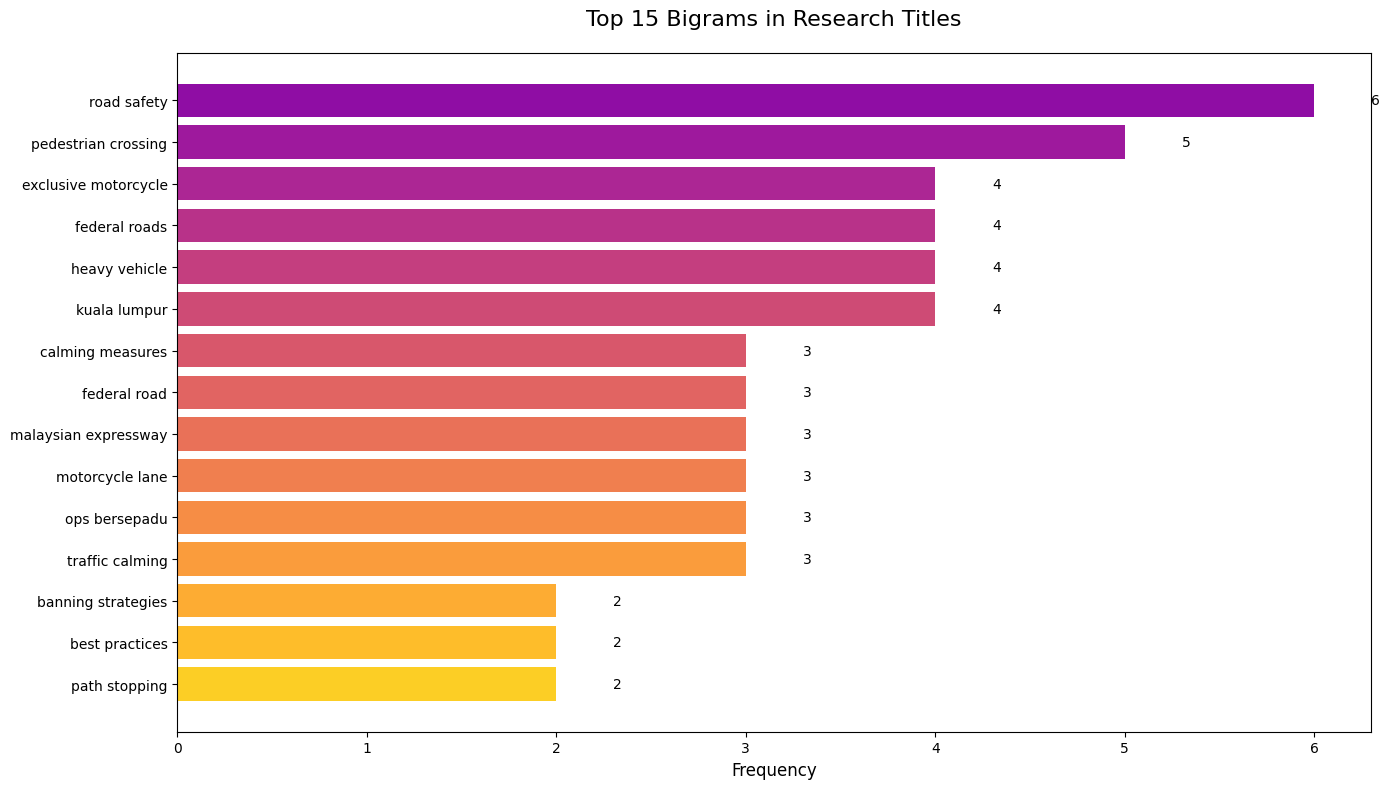

In [23]:
vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=30)
X = vectorizer.fit_transform(df['Clean_Title'])
bigrams = vectorizer.get_feature_names_out()
bigram_counts = X.sum(axis=0).A1

bigram_data = sorted(zip(bigrams, bigram_counts), key=lambda x: x[1], reverse=True)[:15]
bigrams_list, counts = zip(*bigram_data)

plt.figure(figsize=(14, 8))
colors = plt.cm.plasma(np.linspace(0.3, 0.9, len(bigrams_list)))
bars = plt.barh(bigrams_list, counts, color=colors)
plt.xlabel('Frequency', fontsize=12)
plt.title('Top 15 Bigrams in Research Titles', fontsize=16, pad=20)
plt.gca().invert_yaxis()
for bar, count in zip(bars, counts):
    width = bar.get_width()
    plt.text(width + 0.3, bar.get_y() + bar.get_height()/2, f'{count}', ha='left', va='center', fontsize=10)
plt.tight_layout()
plt.show()


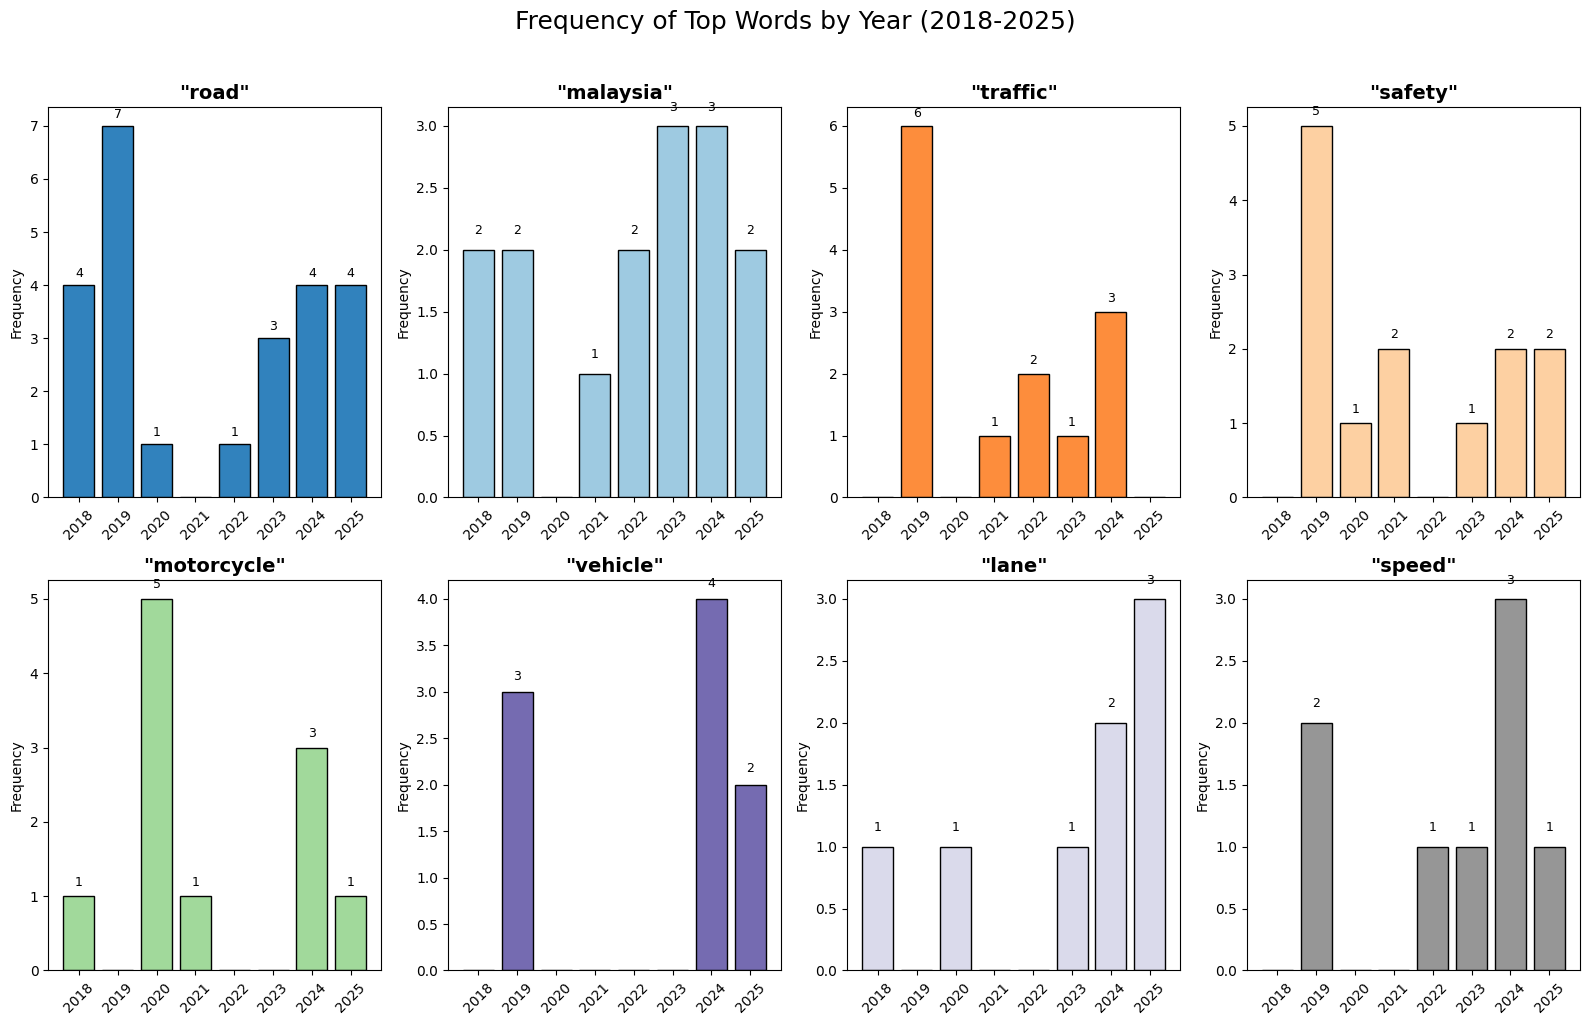

In [24]:
year_col = None
for col in df.columns:
    if 'tahun' in col.lower() or 'year' in col.lower():
        year_col = col
        break

if year_col:
    top_8_words = [word for word, _ in word_freq.most_common(8)]
    years = sorted(df[year_col].unique())
    year_word_data = {year: Counter(' '.join(df[df[year_col] == year]['Clean_Title'].tolist()).split()) for year in years}

    n_cols = 4
    n_rows = 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 10))
    axes = axes.flatten()

    for idx, word in enumerate(top_8_words):
        ax = axes[idx]
        yearly_counts = [year_word_data[year].get(word, 0) for year in years]
        bars = ax.bar(range(len(years)), yearly_counts, color=plt.cm.tab20c(idx/8), edgecolor='black')
        ax.set_title(f'"{word}"', fontsize=14, fontweight='bold')
        ax.set_xticks(range(len(years)))
        ax.set_xticklabels(years, rotation=45)
        ax.set_ylabel('Frequency')
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.1, f'{int(height)}', ha='center', va='bottom', fontsize=9)

    for idx in range(len(top_8_words), len(axes)):
        fig.delaxes(axes[idx])

    plt.suptitle('Frequency of Top Words by Year (2018-2025)', fontsize=18, y=1.02)
    plt.tight_layout()
    plt.show()


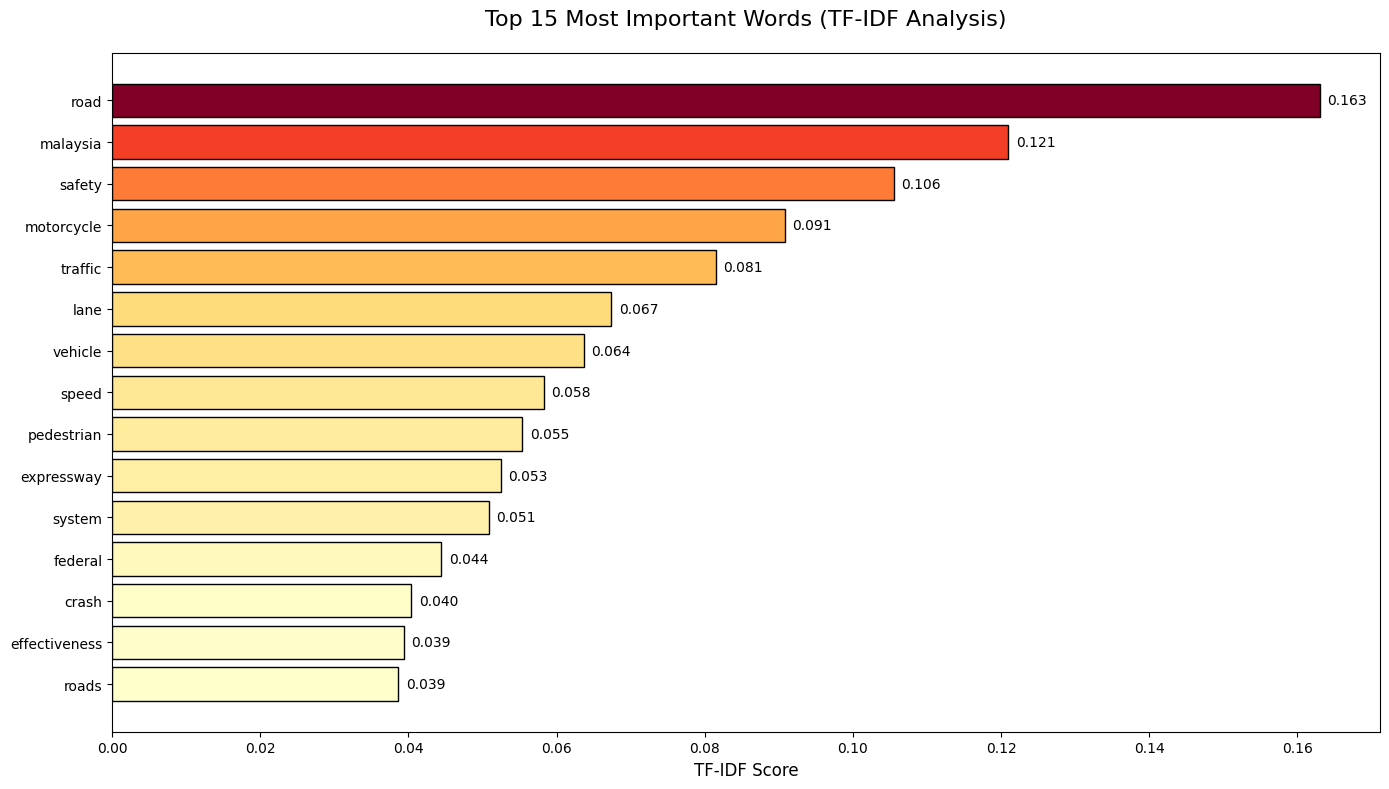

In [25]:
tfidf = TfidfVectorizer(max_features=20, stop_words=list(custom_stopwords))
tfidf_matrix = tfidf.fit_transform(df['Clean_Title'])
feature_names = tfidf.get_feature_names_out()
tfidf_scores = np.asarray(tfidf_matrix.mean(axis=0)).flatten()

sorted_indices = tfidf_scores.argsort()[::-1][:15]
top_tfidf_words = feature_names[sorted_indices]
top_tfidf_scores = tfidf_scores[sorted_indices]

plt.figure(figsize=(14, 8))
norm_scores = (top_tfidf_scores - top_tfidf_scores.min()) / (top_tfidf_scores.max() - top_tfidf_scores.min())
colors = plt.cm.YlOrRd(norm_scores)
bars = plt.barh(top_tfidf_words, top_tfidf_scores, color=colors, edgecolor='black')
plt.xlabel('TF-IDF Score', fontsize=12)
plt.title('Top 15 Most Important Words (TF-IDF Analysis)', fontsize=16, pad=20)
plt.gca().invert_yaxis()
for bar, score in zip(bars, top_tfidf_scores):
    width = bar.get_width()
    plt.text(width + 0.001, bar.get_y() + bar.get_height()/2, f'{score:.3f}', ha='left', va='center', fontsize=10)
plt.tight_layout()
plt.show()


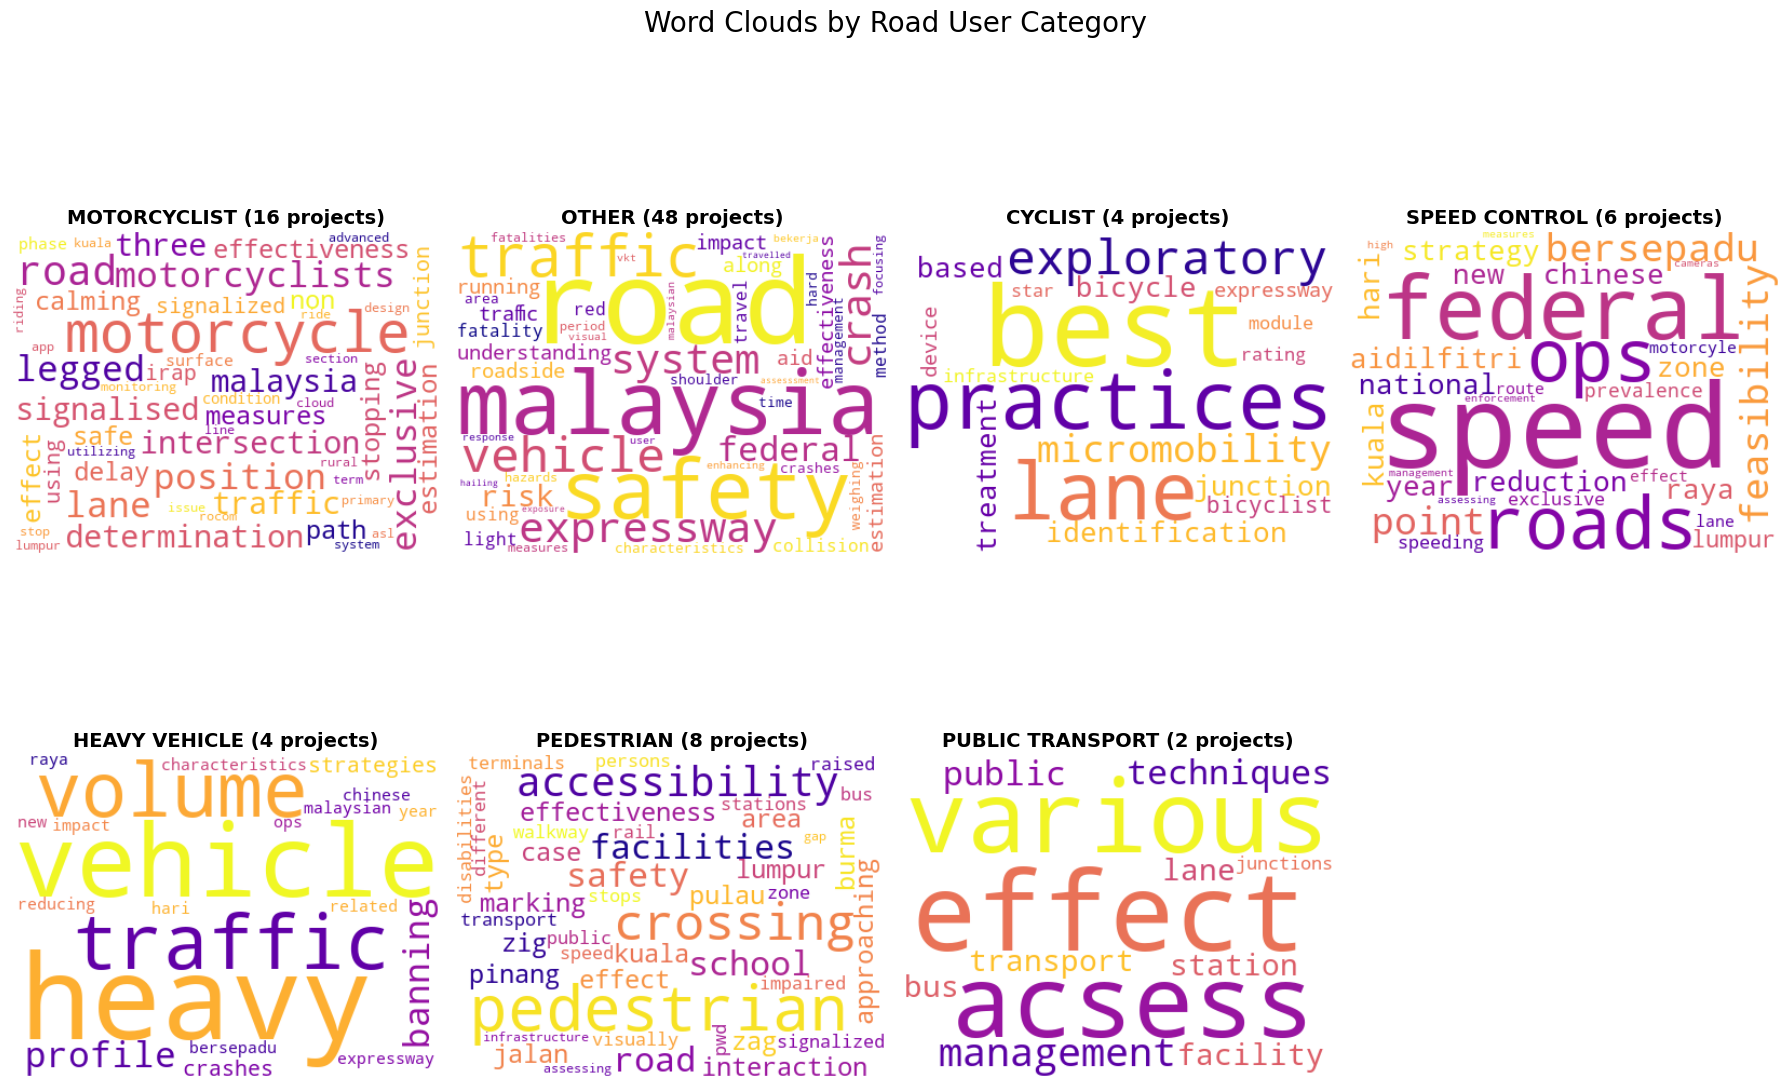

In [26]:
def detect_simple_road_user(title):
    title_lower = str(title).lower()
    if any(word in title_lower for word in ['pedestrian', 'walking', 'crossing', 'school zone']):
        return 'PEDESTRIAN'
    elif any(word in title_lower for word in ['motorcycle', 'motorcyclist', 'moped', 'two-wheeler']):
        return 'MOTORCYCLIST'
    elif any(word in title_lower for word in ['bicycle', 'cyclist', 'micromobility']):
        return 'CYCLIST'
    elif any(word in title_lower for word in ['heavy vehicle', 'truck', 'lorry', 'hgv']):
        return 'HEAVY VEHICLE'
    elif any(word in title_lower for word in ['bus', 'public transport', 'transit']):
        return 'PUBLIC TRANSPORT'
    elif any(word in title_lower for word in ['speed', '30km/h', '50km/h', 'speed limit']):
        return 'SPEED CONTROL'
    else:
        return 'OTHER'

df['Road_User_Category'] = df[title_col].apply(detect_simple_road_user)
categories = df['Road_User_Category'].unique()
n_categories = len(categories)

fig, axes = plt.subplots(2, (n_categories + 1) // 2, figsize=(18, 12))
axes = axes.flatten()

for idx, category in enumerate(categories):
    if idx < len(axes):
        ax = axes[idx]
        category_titles = ' '.join(df[df['Road_User_Category'] == category]['Clean_Title'].tolist())
        if category_titles.strip():
            wordcloud = WordCloud(width=400, height=300, background_color='white', colormap='plasma', max_words=50, stopwords=custom_stopwords).generate(category_titles)
            ax.imshow(wordcloud, interpolation='bilinear')
            ax.set_title(f'{category} ({len(df[df["Road_User_Category"]==category])} projects)', fontsize=14, fontweight='bold')
            ax.axis('off')

for idx in range(len(categories), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle('Word Clouds by Road User Category', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


In [27]:
summary_stats = {
    'Total_Research_Projects': len(df),
    'Total_Words_Analyzed': len(all_clean_titles.split()),
    'Unique_Words': len(set(all_clean_titles.split())),
    'Average_Title_Length': df['Clean_Title'].apply(lambda x: len(x.split())).mean()
}

for key, value in summary_stats.items():
    print(f"{key}: {value:.1f}" if isinstance(value, float) else f"{key}: {value}")

word_freq_df = pd.DataFrame(word_freq.most_common(50), columns=['Word', 'Frequency'])
word_freq_df.to_excel('REER_Word_Frequency_Analysis.xlsx', index=False)

print("Text mining complete. Word frequency data saved to REER_Word_Frequency_Analysis.xlsx")


Total_Research_Projects: 88
Total_Words_Analyzed: 660
Unique_Words: 361
Average_Title_Length: 7.5
Text mining complete. Word frequency data saved to REER_Word_Frequency_Analysis.xlsx
